
--- PCA Variance Explained across Components ---
Component  Individual Variance Ratio  Cumulative Variance Ratio
      PC1                     0.6425                     0.6425
      PC2                     0.1497                     0.7922
      PC3                     0.0296                     0.8218
      PC4                     0.0263                     0.8481
      PC5                     0.0249                     0.8730
      PC6                     0.0219                     0.8948
      PC7                     0.0207                     0.9156
      PC8                     0.0182                     0.9338

--- Model Performance Comparison: Before vs After PCA ---
       Feature Set  Dimensionality  Train Time (s)  Accuracy  Precision   Recall  F1-Score
   Full Sensor Set              14          0.0382  0.961958   0.885191 0.858065  0.871417
PCA (4 Components)               4          0.0145  0.957839   0.866776 0.850000  0.858306

Experiment 13 Completed Successfully


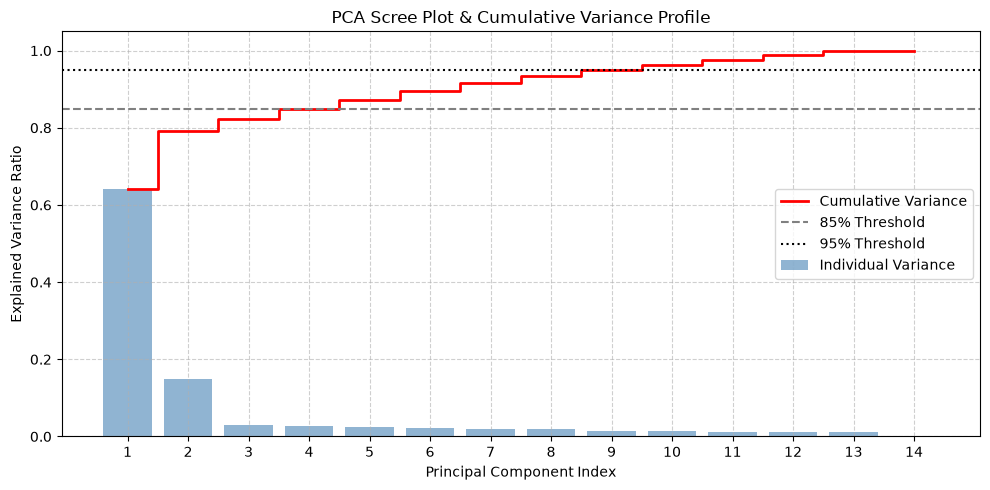

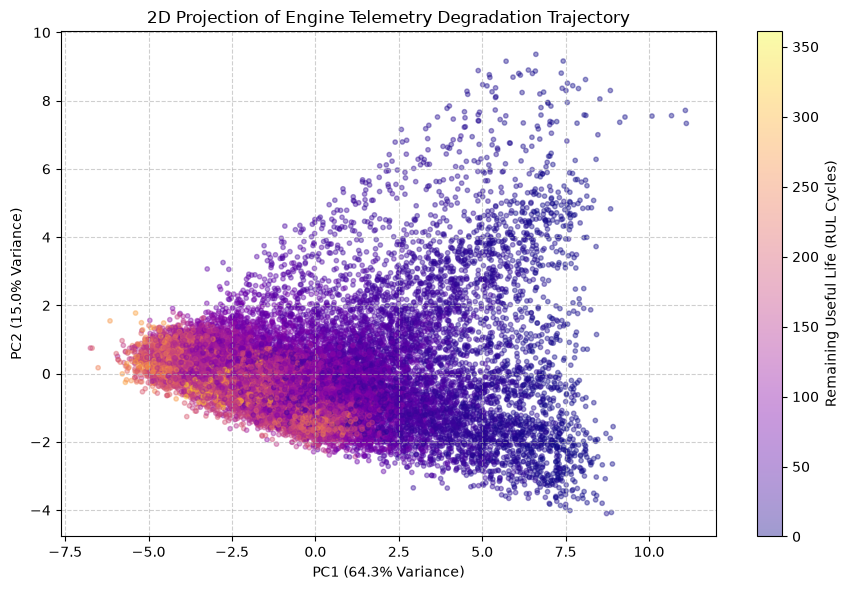

In [1]:
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


# Load C-MAPSS telemetry dataset
cols = ["engine_id", "cycle", "setting_1", "setting_2", "setting_3"] + [f"sensor_{i}" for i in range(1, 22)]
df = pd.read_csv("../dataset/CMAPSSData/train_FD001.txt", sep=r"\s+", header=None, names=cols)

df["RUL"] = df.groupby("engine_id")["cycle"].transform("max") - df["cycle"]
df["failure_soon"] = (df["RUL"] <= 30).astype(int)

# Use all 14 informative degradation sensors
sensor_features = ["sensor_2", "sensor_3", "sensor_4", "sensor_7", "sensor_8", 
                   "sensor_9", "sensor_11", "sensor_12", "sensor_13", "sensor_14", 
                   "sensor_15", "sensor_17", "sensor_20", "sensor_21"]

X = df[sensor_features]
y = df["failure_soon"]

# Standardization prior to PCA is mandatory due to varying sensor units
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 1. Full PCA Decomposition and Variance Analysis
pca_full = PCA(random_state=42)
pca_full.fit(X_scaled)

explained_var = pca_full.explained_variance_ratio_
cum_explained_var = np.cumsum(explained_var)

variance_table = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(explained_var))],
    "Individual Variance Ratio": np.round(explained_var, 4),
    "Cumulative Variance Ratio": np.round(cum_explained_var, 4)
})
print("\n--- PCA Variance Explained across Components ---")
print(variance_table.head(8).to_string(index=False))

# 2. Scree Plot & Cumulative Variance Curve
plt.figure(figsize=(10, 5))
plt.bar(range(1, len(explained_var)+1), explained_var, alpha=0.6, color='steelblue', label='Individual Variance')
plt.step(range(1, len(cum_explained_var)+1), cum_explained_var, where='mid', color='red', lw=2, label='Cumulative Variance')
plt.axhline(y=0.85, color='gray', linestyle='--', label='85% Threshold')
plt.axhline(y=0.95, color='black', linestyle=':', label='95% Threshold')
plt.xlabel("Principal Component Index")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Scree Plot & Cumulative Variance Profile")
plt.xticks(range(1, len(explained_var)+1))
plt.legend(loc='center right')
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

# 3. 2D Projection: Visualizing Degradation in PC Space
pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=df["RUL"], cmap="plasma", alpha=0.4, s=10)
plt.colorbar(scatter, label="Remaining Useful Life (RUL Cycles)")
plt.xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% Variance)")
plt.ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% Variance)")
plt.title("2D Projection of Engine Telemetry Degradation Trajectory")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

# 4. Comparative Model Performance: Before vs After PCA
# Split full feature set and PCA-reduced feature set (n_components=4 retains >85% variance)
n_pca_components = 4
pca_opt = PCA(n_components=n_pca_components, random_state=42)
X_pca_opt = pca_opt.fit_transform(X_scaled)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42, stratify=y)
X_train_pca, X_test_pca, _, _ = train_test_split(X_pca_opt, y, test_size=0.2, random_state=42, stratify=y)

# Model 1: Trained on Full 14 Features
t0 = time.time()
clf_raw = LogisticRegression(max_iter=1000, random_state=42)
clf_raw.fit(X_train_raw, y_train)
t_raw = time.time() - t0
y_pred_raw = clf_raw.predict(X_test_raw)

# Model 2: Trained on PCA 4 Components
t0 = time.time()
clf_pca = LogisticRegression(max_iter=1000, random_state=42)
clf_pca.fit(X_train_pca, y_train)
t_pca = time.time() - t0
y_pred_pca = clf_pca.predict(X_test_pca)

model_comparison = pd.DataFrame({
    "Feature Set": ["Full Sensor Set", f"PCA ({n_pca_components} Components)"],
    "Dimensionality": [X_scaled.shape[1], n_pca_components],
    "Train Time (s)": [round(t_raw, 4), round(t_pca, 4)],
    "Accuracy": [accuracy_score(y_test, y_pred_raw), accuracy_score(y_test, y_pred_pca)],
    "Precision": [precision_score(y_test, y_pred_raw), precision_score(y_test, y_pred_pca)],
    "Recall": [recall_score(y_test, y_pred_raw), recall_score(y_test, y_pred_pca)],
    "F1-Score": [f1_score(y_test, y_pred_raw), f1_score(y_test, y_pred_pca)]
})
print("\n--- Model Performance Comparison: Before vs After PCA ---")
print(model_comparison.to_string(index=False))

print("Experiment 13 Completed Successfully")